In [1]:
from pathlib import Path
import gzip
import hashlib
import json
import platform
import struct
import time
import warnings
from importlib.metadata import version

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, log_loss
from threadpoolctl import threadpool_limits

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists() and (p / "notebooks").is_dir())
RAW = ROOT / "data" / "raw"
SPLITS = ROOT / "data" / "splits"
RESULTS = ROOT / "results" / "knn-comparison"
RESULTS.mkdir(parents=True, exist_ok=True)
SEED = 42
CLASS_NAMES = np.array(["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"])
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
environment = {"python": platform.python_version(), **{name: version(name) for name in ("numpy", "pandas", "scikit-learn", "joblib", "threadpoolctl")}}
display(pd.Series(environment, name="Version"))

python           3.12.0
numpy             2.5.4
pandas            3.0.6
scikit-learn      1.9.1
joblib            1.6.0
threadpoolctl     3.7.0
Name: Version, dtype: str

In [2]:
def read_idx(path):
    with gzip.open(path, "rb") as stream:
        payload = stream.read()
    zero_a, zero_b, dtype_code, dimensions = struct.unpack(">BBBB", payload[:4])
    if (zero_a, zero_b, dtype_code) != (0, 0, 8) or dimensions not in (1, 3):
        raise ValueError(f"Invalid IDX header: {path.name}")
    offset = 4 + 4 * dimensions
    shape = struct.unpack(">" + "I" * dimensions, payload[4:offset])
    values = np.frombuffer(payload, dtype=np.uint8, offset=offset)
    if values.size != np.prod(shape):
        raise ValueError(f"Invalid IDX payload size: {path.name}")
    return values.reshape(shape)

metadata_path = SPLITS / "train-validation-v1.json"
split_path = SPLITS / "train-validation-v1.npz"
if not metadata_path.exists() or not split_path.exists():
    raise FileNotFoundError("Run 01-data-exploration.ipynb first")
split_metadata = json.loads(metadata_path.read_text())
split_sha256 = hashlib.sha256(split_path.read_bytes()).hexdigest()
assert split_sha256 == split_metadata["split_file_sha256"]
training_files = [record for record in split_metadata["files"] if record["filename"].startswith("train-")]
for record in training_files:
    assert hashlib.sha256((RAW / record["filename"]).read_bytes()).hexdigest() == record["sha256"]
images = read_idx(RAW / "train-images-idx3-ubyte.gz")
labels = read_idx(RAW / "train-labels-idx1-ubyte.gz")
with np.load(split_path, allow_pickle=False) as saved:
    train_indices = saved["train_indices"]
    validation_indices = saved["validation_indices"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(len(labels)))
assert np.intersect1d(train_indices, validation_indices).size == 0
X_train = images[train_indices].reshape(len(train_indices), -1).astype(np.float64) / 255.0
X_validation = images[validation_indices].reshape(len(validation_indices), -1).astype(np.float64) / 255.0
y_train = labels[train_indices]
y_validation = labels[validation_indices]
assert np.isfinite(X_train).all() and np.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1
assert 0 <= X_validation.min() <= X_validation.max() <= 1
display(pd.DataFrame({"split": ["Training", "Validation"], "images": [len(y_train), len(y_validation)], "features": [X_train.shape[1], X_validation.shape[1]]}))

,split,images,features
0,Training,48000,784
1,Validation,12000,784


In [3]:
K_VALUES = [3, 5, 9]
COMMON_PARAMETERS = {"weights": "uniform", "algorithm": "brute", "metric": "euclidean", "n_jobs": 1}
models = {}
predictions_by_k = {}
rows = []
for k in K_VALUES:
    candidate = KNeighborsClassifier(n_neighbors=k, **COMMON_PARAMETERS)
    start = time.perf_counter()
    candidate.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    with threadpool_limits(limits=4):
        predictions = candidate.predict(X_validation)
    prediction_seconds = time.perf_counter() - start
    report = classification_report(y_validation, predictions, labels=np.arange(10), output_dict=True, zero_division=0)
    rows.append({"k": k, "validation_accuracy": accuracy_score(y_validation, predictions),
                 "validation_macro_f1": f1_score(y_validation, predictions, average="macro"),
                 "shirt_recall": report["6"]["recall"], "fit_seconds": fit_seconds,
                 "validation_prediction_seconds": prediction_seconds})
    models[k] = candidate
    predictions_by_k[k] = predictions
    pd.DataFrame(rows).to_json(RESULTS / "search-progress.json", orient="records", indent=2)
    print(f"k={k}: accuracy={rows[-1]['validation_accuracy']:.4f}, macro-F1={rows[-1]['validation_macro_f1']:.4f}, prediction seconds={prediction_seconds:.2f}")
comparison = pd.DataFrame(rows)
display(comparison.round(4))
best_k = int(comparison.sort_values(["validation_accuracy", "k"], ascending=[False, False]).iloc[0]["k"])
best_model = models[best_k]
validation_predictions = predictions_by_k[best_k]
print(f"Selected k: {best_k}")

k=3: accuracy=0.8538, macro-F1=0.8534, prediction seconds=2.67


k=5: accuracy=0.8532, macro-F1=0.8524, prediction seconds=2.53


k=9: accuracy=0.8492, macro-F1=0.8484, prediction seconds=2.50


,k,validation_accuracy,validation_macro_f1,shirt_recall,fit_seconds,validation_prediction_seconds
0,3,0.8538,0.8534,0.5892,0.0096,2.6663
1,5,0.8532,0.8524,0.5750,0.0067,2.5266
2,9,0.8492,0.8484,0.5683,0.0068,2.4960


Selected k: 3


In [4]:
logistic_metadata_path = ROOT / "results" / "logistic-regression-regularization" / "run-metadata.json"
model_comparison_rows = [{"model": f"kNN (k={best_k})", **comparison.loc[comparison.k == best_k, ["validation_accuracy", "validation_macro_f1", "shirt_recall"]].iloc[0].to_dict()}]
if logistic_metadata_path.exists():
    logistic_metadata = json.loads(logistic_metadata_path.read_text())
    assert logistic_metadata["split_sha256"] == split_sha256
    logistic_row = next(row for row in logistic_metadata["comparisons"] if row["C"] == logistic_metadata["selected_C"])
    model_comparison_rows.insert(0, {"model": f"Logistic regression (C={logistic_metadata['selected_C']:g})", **{key: logistic_row[key] for key in ("validation_accuracy", "validation_macro_f1", "shirt_recall")}})
model_comparison = pd.DataFrame(model_comparison_rows)
display(model_comparison.round(4))
report = classification_report(y_validation, validation_predictions, labels=np.arange(10), target_names=CLASS_NAMES.tolist(), output_dict=True, zero_division=0)
per_class = pd.DataFrame({name: report[name] for name in CLASS_NAMES}).T
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(4))

,model,validation_accuracy,validation_macro_f1,shirt_recall
0,Logistic regression (C=0.1),0.8540,0.8530,0.5942
1,kNN (k=3),0.8538,0.8534,0.5892


,precision,recall,f1-score,support
T-shirt/top,0.7474,0.8433,0.7925,1200
Trouser,0.9882,0.9775,0.9828,1200
Pullover,0.7171,0.8133,0.7622,1200
Dress,0.9037,0.8600,0.8813,1200
Coat,0.7995,0.7575,0.7779,1200
Sandal,0.9883,0.8425,0.9096,1200
Shirt,0.6746,0.5892,0.6290,1200
Sneaker,0.8862,0.9342,0.9095,1200
Bag,0.9697,0.9592,0.9644,1200
Ankle boot,0.8904,0.9617,0.9247,1200


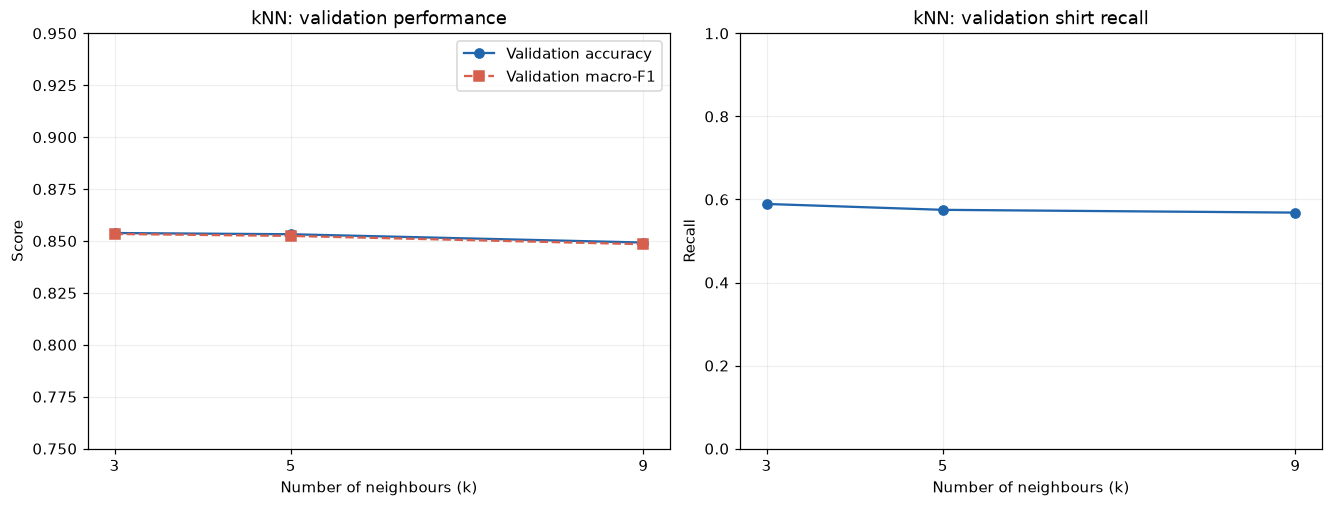

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].plot(comparison.k, comparison.validation_accuracy, "o-", label="Validation accuracy", color="#2166ac")
axes[0].plot(comparison.k, comparison.validation_macro_f1, "s--", label="Validation macro-F1", color="#d6604d")
axes[0].set(title="kNN: validation performance", xlabel="Number of neighbours (k)", ylabel="Score", xticks=K_VALUES, ylim=(0.75, 0.95))
axes[0].legend()
axes[1].plot(comparison.k, comparison.shirt_recall, "o-", color="#2166ac")
axes[1].set(title="kNN: validation shirt recall", xlabel="Number of neighbours (k)", ylabel="Recall", xticks=K_VALUES, ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.2)
fig.savefig(RESULTS / "knn-comparison.png", bbox_inches="tight")
plt.show()

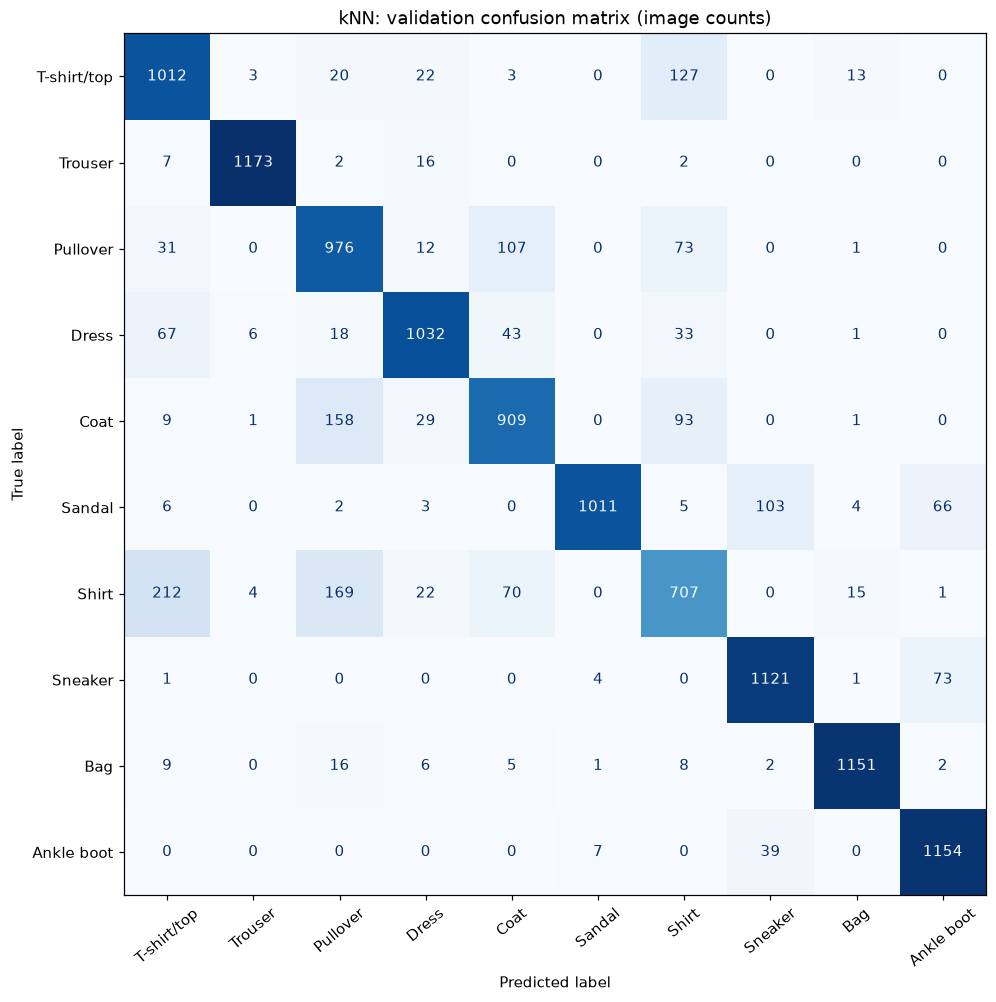

,actual,predicted,images,share_of_actual_class
0,Shirt,T-shirt/top,212,0.1767
1,Shirt,Pullover,169,0.1408
2,Coat,Pullover,158,0.1317
3,T-shirt/top,Shirt,127,0.1058
4,Pullover,Coat,107,0.0892
5,Sandal,Sneaker,103,0.0858
6,Coat,Shirt,93,0.0775
7,Pullover,Shirt,73,0.0608
8,Sneaker,Ankle boot,73,0.0608
9,Shirt,Coat,70,0.0583


In [6]:
matrix = confusion_matrix(y_validation, validation_predictions, labels=np.arange(10))
assert matrix.sum() == len(y_validation)
assert np.isclose(np.trace(matrix) / matrix.sum(), accuracy_score(y_validation, validation_predictions))
fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format="d", xticks_rotation=40, colorbar=False)
ax.set_title("kNN: validation confusion matrix (image counts)")
fig.savefig(RESULTS / "validation-confusion-matrix.png", bbox_inches="tight")
plt.show()
confusions = pd.DataFrame([
    {"actual": CLASS_NAMES[i], "predicted": CLASS_NAMES[j], "images": int(matrix[i,j]), "share_of_actual_class": float(matrix[i,j] / matrix[i].sum())}
    for i in range(10) for j in range(10) if i != j and matrix[i,j] > 0
]).sort_values("images", ascending=False).reset_index(drop=True)
display(confusions.head(10).round(4))

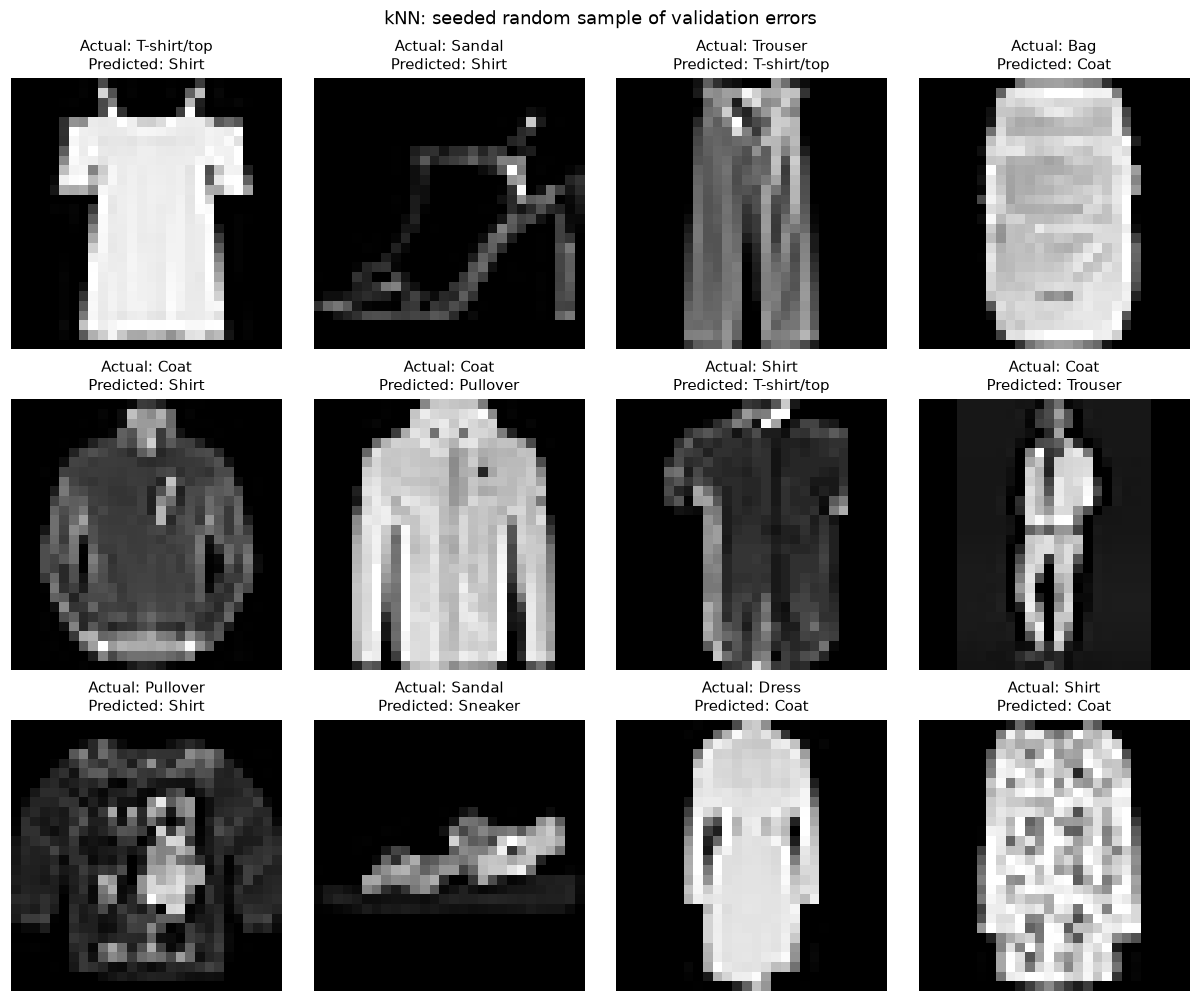

In [7]:
error_positions = np.flatnonzero(validation_predictions != y_validation)
rng = np.random.default_rng(SEED)
selected = rng.choice(error_positions, size=min(12, len(error_positions)), replace=False)
fig, axes = plt.subplots(3, 4, figsize=(11, 9), layout="constrained")
for ax in axes.ravel():
    ax.axis("off")
for ax, position in zip(axes.ravel(), selected):
    ax.imshow(images[validation_indices[position]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Actual: {CLASS_NAMES[y_validation[position]]}\nPredicted: {CLASS_NAMES[validation_predictions[position]]}", fontsize=10)
fig.suptitle("kNN: seeded random sample of validation errors")
fig.savefig(RESULTS / "validation-errors.png", bbox_inches="tight")
plt.show()

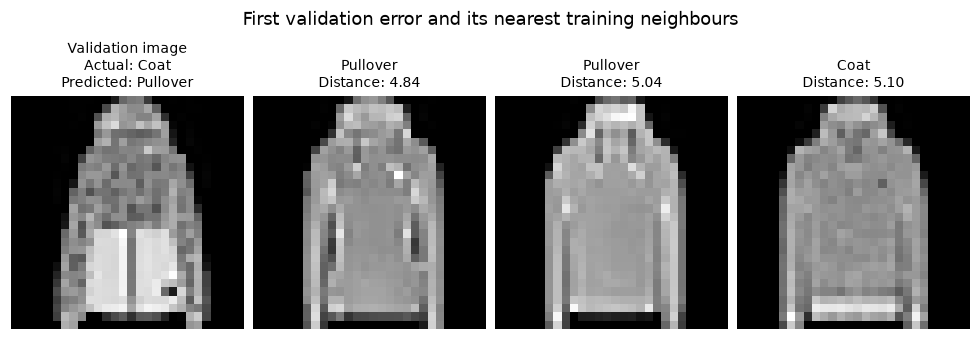

Pullover    2
Coat        1
Name: Votes, dtype: int64

In [8]:
position = int(error_positions[0]) if len(error_positions) else 0
with threadpool_limits(limits=4):
    distances, neighbour_positions = best_model.kneighbors(X_validation[position:position+1])
fig, axes = plt.subplots(1, best_k + 1, figsize=(2.2 * (best_k + 1), 3.5), layout="constrained")
axes[0].imshow(images[validation_indices[position]], cmap="gray", vmin=0, vmax=255)
axes[0].set_title(f"Validation image\nActual: {CLASS_NAMES[y_validation[position]]}\nPredicted: {CLASS_NAMES[validation_predictions[position]]}", fontsize=9)
for ax, index, distance in zip(axes[1:], neighbour_positions[0], distances[0]):
    ax.imshow(images[train_indices[index]], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[y_train[index]]}\nDistance: {distance:.2f}", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.suptitle("First validation error and its nearest training neighbours")
fig.savefig(RESULTS / "nearest-neighbours.png", bbox_inches="tight")
plt.show()
display(pd.Series(CLASS_NAMES[y_train[neighbour_positions[0]]]).value_counts().rename("Votes"))

In [9]:
model_path = RESULTS / "selected-model.joblib"
joblib.dump(best_model, model_path, compress=3)
restored_model = joblib.load(model_path)
verification_positions = np.random.default_rng(SEED).choice(len(y_validation), size=100, replace=False)
with threadpool_limits(limits=4):
    np.testing.assert_array_equal(restored_model.predict(X_validation[verification_positions]), validation_predictions[verification_positions])
comparison.to_csv(RESULTS / "comparison.csv", index=False)
model_comparison.to_csv(RESULTS / "model-comparison.csv", index=False)
per_class.to_csv(RESULTS / "selected-validation-classification-report.csv")
confusions.to_csv(RESULTS / "validation-confusions.csv", index=False)
pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RESULTS / "validation-confusion-matrix.csv")
pd.DataFrame({"source_index": validation_indices, "actual": y_validation, "predicted": validation_predictions}).to_csv(RESULTS / "selected-validation-predictions.csv", index=False)
metadata = {
    "k_values": K_VALUES, "common_parameters": COMMON_PARAMETERS,
    "selection_rule": "Highest validation accuracy; exact ties prefer larger k", "selected_k": best_k,
    "split_sha256": split_sha256, "environment": environment, "source_files": training_files,
    "preprocessing": "float64 pixels / 255, flatten in C order",
    "class_names": CLASS_NAMES.tolist(), "training_count": len(y_train), "validation_count": len(y_validation),
    "test_evaluated": False, "comparisons": rows, "model_comparison": model_comparison_rows,
    "reload_verification_images": len(verification_positions),
    "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
}
(RESULTS / "run-metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved results/knn-comparison artifacts")
print("Reloaded model reproduces predictions on 100 seeded validation images")

Saved results/knn-comparison artifacts
Reloaded model reproduces predictions on 100 seeded validation images
